<a href="https://colab.research.google.com/github/mohammeddyyan/Deep-learning/blob/main/task_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow Version: 2.21.0
Dataset Downloaded Successfully!
           dt  AverageTemperature  AverageTemperatureUncertainty     City  \
0  1849-01-01              26.704                          1.435  Abidjan   
1  1849-02-01              27.434                          1.362  Abidjan   
2  1849-03-01              28.101                          1.612  Abidjan   
3  1849-04-01              26.140                          1.387  Abidjan   
4  1849-05-01              25.427                          1.200  Abidjan   

         Country Latitude Longitude  
0  Côte D'Ivoire    5.63N     3.23W  
1  Côte D'Ivoire    5.63N     3.23W  
2  Côte D'Ivoire    5.63N     3.23W  
3  Côte D'Ivoire    5.63N     3.23W  
4  Côte D'Ivoire    5.63N     3.23W  
Dataset Shape: (239177, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239177 entries, 0 to 239176
Data columns (total 7 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                  

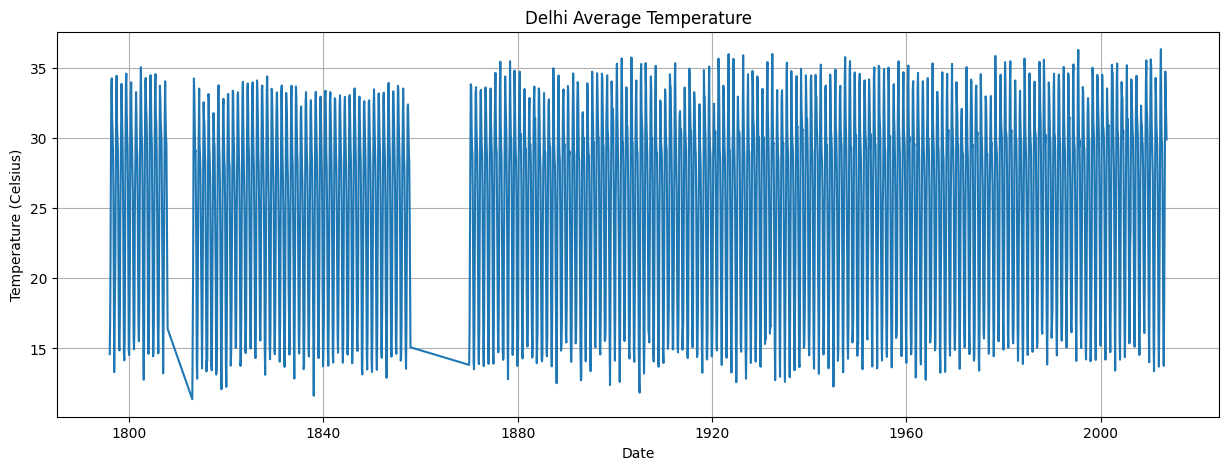

Training Data: (3830, 1)
Testing Data: (958, 1)
Training Input: (3800, 30, 1)
Training Output: (3800, 1)
Testing Input: (958, 30, 1)
Testing Output: (958, 1)

Original Sequences:
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]

Padded Sequences:
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - loss: 0.0321 - mae: 0.1214 - val_loss: 0.0067 - val_mae: 0.0659 - learning_rate: 0.0010
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0064 - mae: 0.0639 - val_loss: 0.0060 - val_mae: 0.0623 - learning_rate: 0.0010
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0058 - mae: 0.0611 - val_loss: 0.0055 - val_mae: 0.0604 - learning_rate: 0.0010
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0053 - mae: 0.0587 - val_loss: 0.0050 - val_mae: 0.0582 - learning_rate: 0.0010
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0048 - mae: 0.0559 - val_loss: 0.0045 - val_mae: 0.0548 - learning_rate: 0.0010
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0044 - mae: 0.0526 - val_loss: 0.0039 - val_mae: 0.0502 - learning_rate: 0.0010
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0037 - mae: 0.0480 - val_loss: 0.0033 - val_mae: 0.0454 - learning_rate: 0.0010

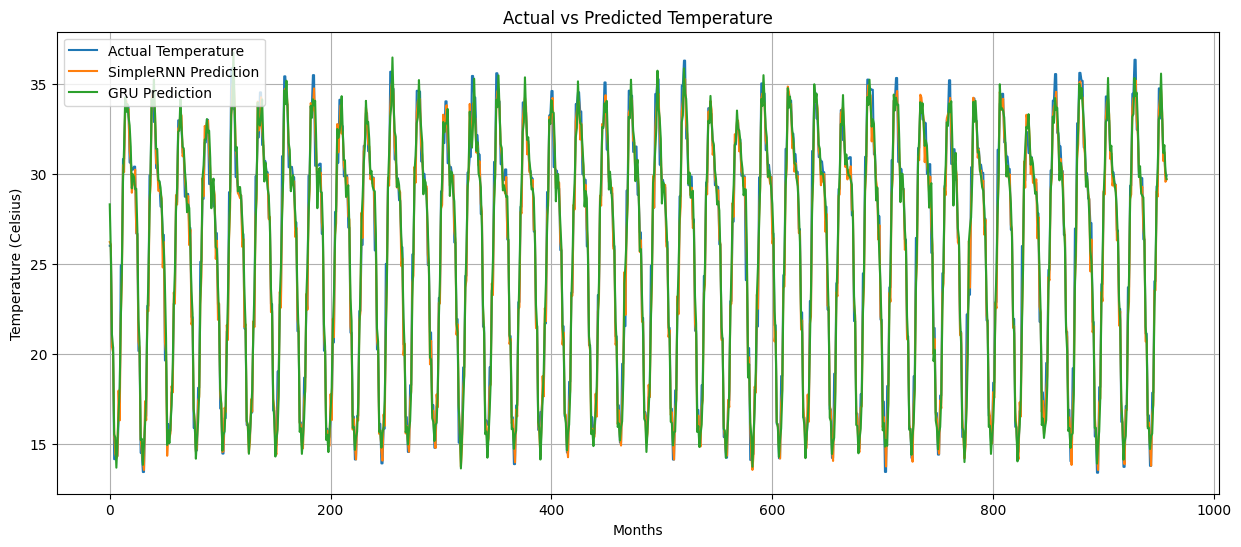

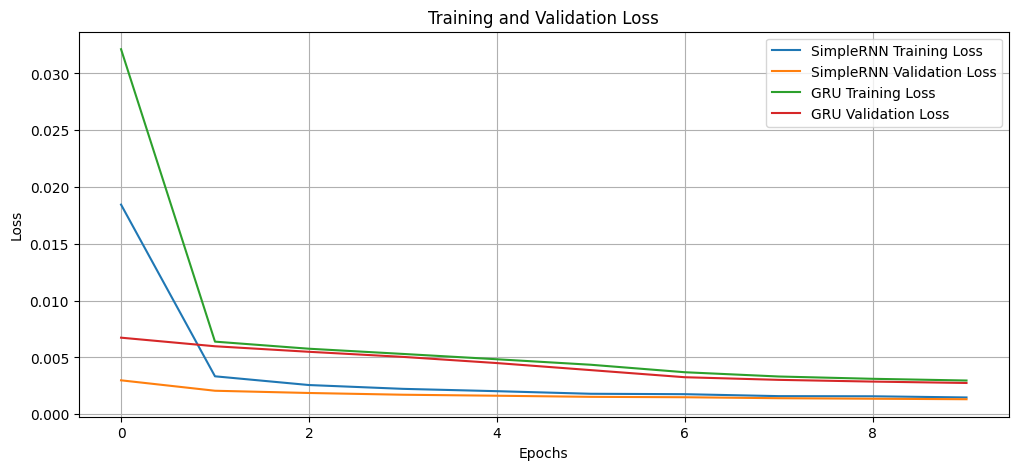


FINAL MODEL COMPARISON
       Model       MSE       MAE
0  SimpleRNN  0.801422  0.647905
1        GRU  1.668676  1.005924

SimpleRNN performs better than GRU

Experiment Completed Successfully!


In [ ]:

# TASK 7: TIME SERIES FORECASTING USING SimpleRNN AND GRU

# 1. Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Input
from tensorflow.keras.utils import timeseries_dataset_from_array

import warnings
warnings.filterwarnings("ignore")

print("TensorFlow Version:", tf.__version__)


# 2. Download Dataset Automatically

url = "https://raw.githubusercontent.com/urgedata/pythondata/master/examples/climate-change-earth-surface-temperature-data/GlobalLandTemperaturesByMajorCity.csv"

df = pd.read_csv(url)

print("Dataset Downloaded Successfully!")
print(df.head())
print("Dataset Shape:", df.shape)


# 3. Explore Dataset

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Cities:", df["City"].nunique())


# 4. Extract Delhi Temperature Data

city_df = df[
    (df["City"].str.contains("Delhi", case=False, na=False)) &
    (df["Country"] == "India")
].copy()

city_df = city_df.dropna(subset=["AverageTemperature"])

city_df["dt"] = pd.to_datetime(city_df["dt"])

city_df = city_df.sort_values("dt")

city_df.reset_index(drop=True, inplace=True)

print("\nDelhi Dataset:")
print(city_df.head())

print("Delhi Records:", len(city_df))


# 5. Extract Temperature

temperature = city_df[["AverageTemperature"]]

print("\nTemperature Shape:", temperature.shape)


# 6. Visualize Temperature

plt.figure(figsize=(15,5))

plt.plot(city_df["dt"], temperature)

plt.title("Delhi Average Temperature")

plt.xlabel("Date")

plt.ylabel("Temperature (Celsius)")

plt.grid(True)

plt.show()


# 7. Normalize Data and Split Dataset

lookback = 30

train_size = int(len(temperature) * 0.80)

train_raw = temperature.iloc[:train_size]

test_raw = temperature.iloc[train_size:]

scaler = MinMaxScaler()

train = scaler.fit_transform(train_raw)

test = scaler.transform(test_raw)

print("Training Data:", train.shape)
print("Testing Data:", test.shape)


# 8. Create Time Series Sequences

def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(len(data) - lookback):

        X.append(data[i:i+lookback])

        y.append(data[i+lookback])

    return np.array(X), np.array(y)


X_train, y_train = create_sequences(train, lookback)

# Include previous training observations as context
combined = np.concatenate([train[-lookback:], test])

X_test, y_test = create_sequences(combined, lookback)

print("Training Input:", X_train.shape)
print("Training Output:", y_train.shape)

print("Testing Input:", X_test.shape)
print("Testing Output:", y_test.shape)


# 9. Create TensorFlow Datasets

batch_size = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).batch(batch_size)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(batch_size)


# 10. Demonstrate Sequence Padding

sample_sequences = [
    [1, 2, 3],
    [4, 5],
    [6, 7, 8, 9]
]

padded = pad_sequences(
    sample_sequences,
    maxlen=5,
    padding="pre"
)

print("\nOriginal Sequences:")
print(sample_sequences)

print("\nPadded Sequences:")
print(padded)


# 11. Build SimpleRNN Model

simple_rnn = Sequential([

    Input(shape=(lookback, 1)),

    SimpleRNN(64, activation="tanh"),

    Dense(32, activation="relu"),

    Dense(1)

])

simple_rnn.summary()


# 12. Compile SimpleRNN

simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)


# 13. Define Callbacks

callbacks_rnn = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3

    )

]


# 14. Train SimpleRNN

history_rnn = simple_rnn.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks_rnn

)


# 15. Evaluate SimpleRNN

loss_rnn, mae_rnn = simple_rnn.evaluate(test_dataset)

print("\nSimpleRNN Loss:", loss_rnn)

print("SimpleRNN MAE:", mae_rnn)


# 16. Build GRU Model

gru_model = Sequential([

    Input(shape=(lookback, 1)),

    GRU(64, activation="tanh"),

    Dense(32, activation="relu"),

    Dense(1)

])

gru_model.summary()


# 17. Compile GRU

gru_model.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)


# 18. Train GRU

callbacks_gru = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3

    )

]

history_gru = gru_model.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks_gru

)


# 19. Evaluate GRU

loss_gru, mae_gru = gru_model.evaluate(test_dataset)

print("\nGRU Loss:", loss_gru)

print("GRU MAE:", mae_gru)


# 20. Generate Predictions

pred_rnn = simple_rnn.predict(X_test)

pred_gru = gru_model.predict(X_test)


# 21. Convert Predictions to Original Scale

actual = scaler.inverse_transform(y_test)

pred_rnn = scaler.inverse_transform(pred_rnn)

pred_gru = scaler.inverse_transform(pred_gru)


# 22. Calculate Error Metrics

mse_rnn = mean_squared_error(actual, pred_rnn)

mse_gru = mean_squared_error(actual, pred_gru)

mae_rnn_original = mean_absolute_error(actual, pred_rnn)

mae_gru_original = mean_absolute_error(actual, pred_gru)

print("\nSimpleRNN MSE:", mse_rnn)

print("GRU MSE:", mse_gru)

print("SimpleRNN MAE:", mae_rnn_original)

print("GRU MAE:", mae_gru_original)


# 23. Plot Actual vs Predicted Temperature

plt.figure(figsize=(15,6))

plt.plot(actual, label="Actual Temperature")

plt.plot(pred_rnn, label="SimpleRNN Prediction")

plt.plot(pred_gru, label="GRU Prediction")

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Months")

plt.ylabel("Temperature (Celsius)")

plt.legend()

plt.grid(True)

plt.show()


# 24. Plot Training and Validation Loss

plt.figure(figsize=(12,5))

plt.plot(
    history_rnn.history["loss"],
    label="SimpleRNN Training Loss"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="SimpleRNN Validation Loss"
)

plt.plot(
    history_gru.history["loss"],
    label="GRU Training Loss"
)

plt.plot(
    history_gru.history["val_loss"],
    label="GRU Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()


# 25. Compare Both Models

comparison = pd.DataFrame({

    "Model": ["SimpleRNN", "GRU"],

    "MSE": [mse_rnn, mse_gru],

    "MAE": [mae_rnn_original, mae_gru_original]

})

print("\nFINAL MODEL COMPARISON")

print(comparison)


# 26. Final Result

if mse_gru < mse_rnn:

    print("\nGRU performs better than SimpleRNN")

else:

    print("\nSimpleRNN performs better than GRU")

print("\nExperiment Completed Successfully!")
